# Event detection from continuous tracking

Build possession and pass candidates from player–ball proximity, temporal stability and ball movement.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Nearest-player possession candidates
Compute Euclidean player–ball distance for each frame. A two-metre radius is a chosen teaching threshold. Ball height filters flyovers, but duels and missing observations still require uncertainty. Supplied possession is useful for comparison, not a model input here.

,period,start,end,player,team,frames,duration_s
segment,,,,,,,
16,1,56,58,51050,1802,3,0.3
58,1,100,104,797298,1802,5,0.5
59,1,105,109,966114,871,5,0.5
73,1,123,127,560989,871,5,0.5
75,1,129,132,560882,1802,4,0.4
110,1,170,187,965697,1802,18,1.8
122,1,199,212,51050,1802,14,1.4
135,1,225,242,560983,1802,18,1.8
143,1,250,261,560986,1802,12,1.2


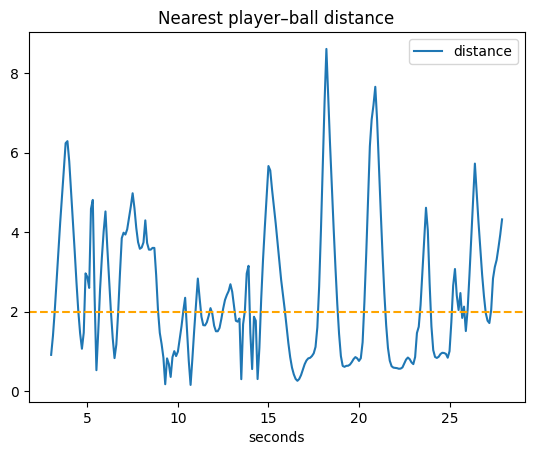

In [2]:
joined=observed.merge(wide[['period_id','frame_id','ball_x','ball_y','ball_z']],on=['period_id','frame_id'],validate='many_to_one')
joined['distance']=np.hypot(joined.x-joined.ball_x,joined.y-joined.ball_y)
valid=joined.dropna(subset=['distance'])
nearest=valid.loc[valid.groupby(['period_id','frame_id']).distance.idxmin()].sort_values(['period_id','frame_id']).copy()
nearest['candidate']=nearest.player_id.where(nearest.distance.le(2)&nearest.ball_z.fillna(0).le(2))
nearest['break']=nearest.period_id.ne(nearest.period_id.shift())|nearest.frame_id.diff().ne(1)|nearest.candidate.ne(nearest.candidate.shift())
nearest['segment']=nearest['break'].cumsum()
segments=nearest.groupby('segment').agg(period=('period_id','first'),start=('frame_id','min'),end=('frame_id','max'),player=('candidate','first'),team=('team_id','first'),frames=('frame_id','size'))
segments['duration_s']=segments.frames/10
stable=segments[segments.player.notna()&segments.duration_s.ge(.3)].copy()
display(stable.head(12))
nearest.head(250).plot(x='seconds',y='distance',title='Nearest player–ball distance');plt.axhline(2,color='orange',ls='--');plt.show()

## Release, transit and reception
Pair successive stable possession segments. A same-team identity change with finite ball displacement is a pass candidate. Limit the gap and reject missing ball trajectories. Interceptions, dribbles near teammates, deflections and aerial passes can still fool this baseline. Never equate these rows with verified pass events.

,period,release,reception,passer,receiver,travel_s,displacement_m
0,1,109,123,966114,560989,1.4,10.225380
1,1,132,170,560882,965697,3.8,27.147361
2,1,187,199,965697,51050,1.2,17.012010
3,1,212,225,51050,560983,1.3,16.841954
4,1,242,250,560983,560986,0.8,8.693590
5,1,343,358,11897,966114,1.5,14.703496
6,1,368,376,966114,795530,0.8,5.110773
7,1,385,398,795530,560984,1.3,16.305760
8,1,569,574,287934,51050,0.5,4.323806
9,1,1262,1281,51002,560986,1.9,7.681881


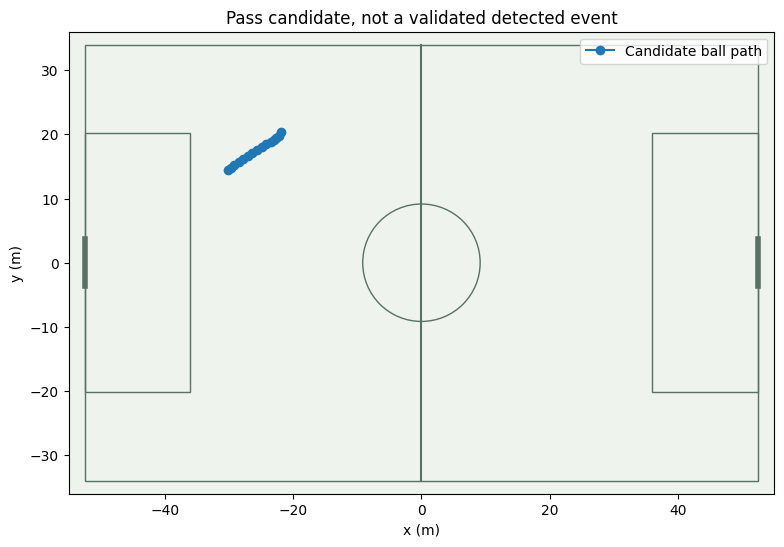

In [3]:
candidates=[]
for a,b in zip(stable.itertuples(),list(stable.itertuples())[1:]):
    if a.period!=b.period or a.player==b.player or a.team!=b.team:continue
    gap=b.start-a.end
    path=wide[wide.period_id.eq(a.period)&wide.frame_id.between(a.end,b.start)].sort_values('frame_id')
    if not 1<=gap<=40 or len(path)!=gap+1 or path[['ball_x','ball_y']].isna().any().any():continue
    displacement=np.linalg.norm(path[['ball_x','ball_y']].iloc[-1]-path[['ball_x','ball_y']].iloc[0])
    if displacement<3:continue
    candidates.append(dict(period=a.period,release=a.end,reception=b.start,passer=a.player,receiver=b.player,travel_s=gap/10,displacement_m=displacement))
passes=pd.DataFrame(candidates,columns=['period','release','reception','passer','receiver','travel_s','displacement_m'])
display(passes.head(10))
fig,ax=plt.subplots(figsize=(10,6));pitch(ax)
if len(passes):
    p=passes.iloc[0];path=wide[wide.period_id.eq(p.period)&wide.frame_id.between(p.release,p.reception)]
    ax.plot(path.ball_x,path.ball_y,'o-',label='Candidate ball path');ax.legend()
ax.set_title('Pass candidate, not a validated detected event');plt.show()

## Timing-aware evaluation
For labeled events, a correct type and passer/receiver should also match within an explicit timing tolerance. Use one-to-one matching so multiple candidates cannot all claim the same true event. Tune thresholds only on training/validation matches. The function below measures timing matches, and can be applied within each event type and player pairing.

In [4]:
from scipy.optimize import linear_sum_assignment
def timing_scores(predicted,truth,tolerance_s=.5):
    predicted=np.asarray(predicted);truth=np.asarray(truth)
    if not len(predicted) or not len(truth):return {'tp':0,'fp':len(predicted),'fn':len(truth)}
    delta=np.abs(predicted[:,None]-truth[None,:])
    # A large penalty first maximizes the count of eligible one-to-one matches.
    cost=np.where(delta<=tolerance_s,delta,1e6)
    rows,cols=linear_sum_assignment(cost);tp=int((delta[rows,cols]<=tolerance_s).sum())
    return {'tp':tp,'fp':len(predicted)-tp,'fn':len(truth)-tp}
assert timing_scores([1,1.1],[1],.2)=={'tp':1,'fp':1,'fn':0}
print('Synthetic unit check only:',timing_scores([1,3],[1.1,5],.2))

Synthetic unit check only: {'tp': 1, 'fp': 1, 'fn': 1}


**Tradeoff:** interpretable and inexpensive, but robust event recovery needs ball dynamics, aerial handling and video-reviewed labels. See [PathCRF](https://github.com/hyunsungkim-ds/pathcrf) for a richer research direction; this notebook does not reproduce it.